# 03 - Parameter Selection (Tasks 2a & 2b)

We estimate the NARX structure in two short steps.

1. Estimate delay $d$ from cross-correlation (use causal lags only: $k \geq 0$).
2. Select $(n_a, n_b)$ with validation NMSE using a Ridge baseline.

Then we evaluate the MIMO recursive rollout used for long-horizon prediction.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

if (Path.cwd() / 'src').exists():
    PROJECT_ROOT = Path.cwd()
else:
    PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

np.set_printoptions(suppress=True, precision=4)

In [2]:
def build_narx_features(u, y, d, na, nb):
    u = np.asarray(u, dtype=float)
    y = np.asarray(y, dtype=float)

    horizon = max(d + na, nb)
    rows = []
    targets = []

    for k in range(horizon, len(y) - 1):
        feats = []
        for lag in range(d, d + na + 1):
            feats.extend(y[k - lag].tolist())
        for lag in range(0, nb + 1):
            feats.extend(u[k - lag].tolist())
        rows.append(feats)
        targets.append(y[k + 1])

    if not rows:
        return np.empty((0, 0)), np.empty((0, y.shape[1]))

    return np.asarray(rows), np.asarray(targets)


def rmse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def nmse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.sum((y_true - np.mean(y_true, axis=0, keepdims=True)) ** 2)
    if denom == 0:
        return float('inf')
    num = np.sum((y_true - y_pred) ** 2)
    return float(num / denom)

In [3]:
dataset_path = PROJECT_ROOT / 'data/raw/StudentdataNARX.npz'
if not dataset_path.exists():
    raise FileNotFoundError(f'Dataset not found: {dataset_path}')

data = np.load(dataset_path)
required_keys = ['Utr', 'Ytr', 'Uts1', 'Uts2']
missing = [k for k in required_keys if k not in data.files]
if missing:
    raise KeyError(f'Missing arrays in dataset: {missing}')

Utr = np.asarray(data['Utr'], dtype=float)
Ytr = np.asarray(data['Ytr'], dtype=float)
Uts1 = np.asarray(data['Uts1'], dtype=float)
Uts2 = np.asarray(data['Uts2'], dtype=float)

print(f'Loaded dataset: {dataset_path.resolve()}')
print(f'Utr shape={Utr.shape}, Ytr shape={Ytr.shape}, Uts1 shape={Uts1.shape}, Uts2 shape={Uts2.shape}')

Loaded dataset: C:\Users\pc\Desktop\M2\ML-stat\project\data\raw\StudentdataNARX.npz
Utr shape=(1000, 2), Ytr shape=(1000, 2), Uts1 shape=(1000, 2), Uts2 shape=(1000, 2)


## Step 1 - Cross-Correlation

We use cross-correlation to get an initial range for delay $d$.

- Keep only causal lags ($k \geq 0$).
- Use pairwise CCF peaks as a guide, then validate with grid search.

In [4]:
def cross_correlation(y, u, max_lag=40):
    y_c = y - y.mean()
    u_c = u - u.mean()
    full_corr = np.correlate(y_c, u_c, mode='full')
    N = len(y)
    lags = np.arange(-(N - 1), N)

    norm = np.sqrt(np.sum(y_c**2) * np.sum(u_c**2))
    full_corr = full_corr / (norm + 1e-12)

    mask = (lags >= -max_lag) & (lags <= max_lag)
    return lags[mask], full_corr[mask]


nu, ny = Utr.shape[1], Ytr.shape[1]
max_lag = 40
peak_lags = {}

for i in range(nu):
    for j in range(ny):
        lags, corr = cross_correlation(Ytr[:, j], Utr[:, i], max_lag=max_lag)
        pos_mask = lags >= 0
        peak_pos = int(lags[pos_mask][np.argmax(np.abs(corr[pos_mask]))])
        peak_lags[(i, j)] = peak_pos

print('Positive-lag peaks per (input, output) pair:')
for (i, j), lag in peak_lags.items():
    print(f'  u{i+1} -> y{j+1}: peak at lag {lag}')

peak_values = np.array(list(peak_lags.values()), dtype=int)
d_min = int(np.min(peak_values))
d_med = int(np.median(peak_values))

# Wider search so d is not forced near 0
max_d = 8
baseline = set(range(0, 5))
around_med = set(range(max(0, d_med - 2), d_med + 4))
around_min = set(range(max(0, d_min - 1), d_min + 3))
d_candidates = sorted(d for d in (baseline | around_med | around_min) if 0 <= d <= max_d)

print(f'\nCCF min peak: {d_min}, median peak: {d_med}')
print(f'Will test d in {d_candidates} during grid search')

Positive-lag peaks per (input, output) pair:
  u1 -> y1: peak at lag 1
  u1 -> y2: peak at lag 1
  u2 -> y1: peak at lag 1
  u2 -> y2: peak at lag 1

CCF min peak: 1, median peak: 1
Will test d in [0, 1, 2, 3, 4] during grid search


In [5]:
def fit_mimo_ridge(X_train, Y_train, alpha=1.0):
    model_y1 = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    model_y2 = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    model_y1.fit(X_train, Y_train[:, 0])
    model_y2.fit(X_train, Y_train[:, 1])
    return model_y1, model_y2


def build_masks(n_samples, horizon, val_ratio=0.30):
    split_idx  = int(n_samples * (1.0 - val_ratio))
    target_idx = np.arange(horizon + 1, n_samples)
    train_mask = target_idx < split_idx
    val_mask   = ~train_mask
    return split_idx, target_idx, train_mask, val_mask


def grid_search_orders(U, Y, grid, val_ratio=0.30, alpha=1.0):
    rows = []
    for params in ParameterGrid(grid):
        d  = int(params['d'])
        na = int(params['na'])
        nb = int(params['nb'])

        X, Y_next = build_narx_features(U, Y, d=d, na=na, nb=nb)
        if X.size == 0:
            continue

        horizon = max(d + na, nb)
        split_idx, _, train_mask, val_mask = build_masks(len(Y), horizon, val_ratio)

        if train_mask.sum() < 30 or val_mask.sum() < 30:
            continue

        model_y1, model_y2 = fit_mimo_ridge(X[train_mask], Y_next[train_mask], alpha)
        Y_val_pred = np.column_stack([
            model_y1.predict(X[val_mask]),
            model_y2.predict(X[val_mask]),
        ])

        rows.append({
            'd': d, 'na': na, 'nb': nb,
            'split_idx': split_idx,
            'n_features': int(X.shape[1]),
            'n_train': int(train_mask.sum()),
            'n_val':   int(val_mask.sum()),
            'nmse_val': float(nmse(Y_next[val_mask], Y_val_pred)),
            'rmse_val': float(rmse(Y_next[val_mask], Y_val_pred)),
        })

    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows).sort_values(['nmse_val', 'rmse_val']).reset_index(drop=True)


def recursive_rollout_mimo(U, model_y1, model_y2, d, na, nb, y_prefix=None):
    U = np.asarray(U, dtype=float)
    n_steps, n_inputs = U.shape
    Y_hat = np.zeros((n_steps, 2), dtype=float)

    start = 0
    if y_prefix is not None and len(y_prefix) > 0:
        prefix_len = min(len(y_prefix), n_steps)
        Y_hat[:prefix_len] = y_prefix[:prefix_len]
        start = prefix_len

    for k in range(start, n_steps):
        feats = []
        for lag in range(d, d + na + 1):
            idx = k - lag
            feats.extend(Y_hat[idx].tolist() if idx >= 0 else [0.0, 0.0])
        for lag in range(0, nb + 1):
            idx = k - lag
            feats.extend(U[idx].tolist() if idx >= 0 else [0.0] * n_inputs)

        xk = np.asarray(feats, dtype=float).reshape(1, -1)
        Y_hat[k, 0] = model_y1.predict(xk)[0]
        Y_hat[k, 1] = model_y2.predict(xk)[0]

    return Y_hat

## Step 2 - Grid Search over $(n_a, n_b)$

Using the $d$ candidates from Step 1, we search over $(n_a, n_b)$.

For each configuration:
1. Build lagged regressors
2. Train two Ridge models on the first 70%
3. Evaluate one-step NMSE on the last 30%

We use one-step (teacher forcing) for order selection so we compare structure quality before recursive drift appears.

In [6]:
order_grid = {
    'd':  d_candidates,         # from cross-correlation + small window
    'na': [1, 2, 3, 4, 5, 6],
    'nb': [1, 2, 3, 4, 5, 6],
}

val_ratio = 0.30
results   = grid_search_orders(Utr, Ytr, order_grid, val_ratio=val_ratio, alpha=1.0)

if results.empty:
    raise RuntimeError('Grid search returned no valid configuration.')

best        = results.iloc[0]
best_orders = {'d': int(best['d']), 'na': int(best['na']), 'nb': int(best['nb'])}

print('Top candidate structures (sorted by validation NMSE):')
print(results[['d', 'na', 'nb', 'nmse_val', 'rmse_val', 'n_features']].head(10).to_string(index=False))
print()
print('Selected orders:', best_orders)

Top candidate structures (sorted by validation NMSE):
 d  na  nb  nmse_val  rmse_val  n_features
 4   6   5  0.363161  0.288696          26
 4   6   6  0.363419  0.288799          28
 4   6   4  0.364789  0.289343          24
 0   5   6  0.366843  0.290156          26
 4   6   3  0.367132  0.290270          22
 4   6   2  0.367451  0.290396          20
 0   6   6  0.367474  0.290406          28
 0   4   6  0.367559  0.290439          24
 0   5   5  0.367585  0.290450          24
 0   6   5  0.367746  0.290513          26

Selected orders: {'d': 4, 'na': 6, 'nb': 5}


In [7]:
d_star = best_orders['d']
sub = results[results['d'] == d_star].copy()

print(f'Best d from search: {d_star}')
print('Top 12 (na, nb) for this d:')
print(sub[['na', 'nb', 'nmse_val', 'rmse_val']].head(12).to_string(index=False))

Best d from search: 4
Top 12 (na, nb) for this d:
 na  nb  nmse_val  rmse_val
  6   5  0.363161  0.288696
  6   6  0.363419  0.288799
  6   4  0.364789  0.289343
  6   3  0.367132  0.290270
  6   2  0.367451  0.290396
  6   1  0.369874  0.291353
  1   6  0.369968  0.291390
  5   6  0.370665  0.291664
  5   5  0.370676  0.291668
  1   5  0.370695  0.291675
  2   6  0.371422  0.291962
  2   5  0.371595  0.292030


### Results from parameter search

The selected orders are printed from the search results.
Focus on NMSE ranking and check if nearby settings are close.
If several settings are close, prefer the simpler one.

## Task 2(b) - MIMO 

- MIMO handling: two output models share one regressor built from lagged $y_1,y_2,u_1,u_2$.
- Long horizon: recursive rollout, because test outputs are not available.

We keep recursive rollout because it matches the project setup. The next cell measures its error growth.

In [8]:
d  = best_orders['d']
na = best_orders['na']
nb = best_orders['nb']

X_all, Y_next = build_narx_features(Utr, Ytr, d=d, na=na, nb=nb)
horizon       = max(d + na, nb)
split_idx, _, train_mask, val_mask = build_masks(len(Ytr), horizon, val_ratio)

model_y1, model_y2 = fit_mimo_ridge(X_all[train_mask], Y_next[train_mask], alpha=1.0)

# one-step: uses true past outputs
Y_val_one_step = np.column_stack([
    model_y1.predict(X_all[val_mask]),
    model_y2.predict(X_all[val_mask]),
])
nmse_os = nmse(Y_next[val_mask], Y_val_one_step)
rmse_os = rmse(Y_next[val_mask], Y_val_one_step)

# recursive: feeds back predictions
Y_roll         = recursive_rollout_mimo(Utr, model_y1, model_y2, d=d, na=na, nb=nb,
                                        y_prefix=Ytr[:split_idx])
Y_val_rec      = Y_roll[split_idx:]
nmse_rec       = nmse(Ytr[split_idx:], Y_val_rec)
rmse_rec       = rmse(Ytr[split_idx:], Y_val_rec)

metrics_table = pd.DataFrame([
    {'strategy': 'one_step_teacher_forcing', 'NMSE': nmse_os,  'RMSE': rmse_os},
    {'strategy': 'recursive_rollout',        'NMSE': nmse_rec, 'RMSE': rmse_rec},
])
print('Validation metrics for Task 2(b):')
print(metrics_table.to_string(index=False))
print()
print(f'Recursive vs one-step NMSE ratio: {nmse_rec / max(nmse_os, 1e-12):.3f}')

Validation metrics for Task 2(b):
                strategy     NMSE     RMSE
one_step_teacher_forcing 0.363161 0.288696
       recursive_rollout 1.561057 0.598551

Recursive vs one-step NMSE ratio: 4.299


### Interpretation

Recursive NMSE is higher than one-step NMSE, which is expected when predictions are fed back.
For a 1000-step rollout from zero initial conditions, this effect can be stronger.
So this is a baseline; stronger models may reduce long-horizon error accumulation.

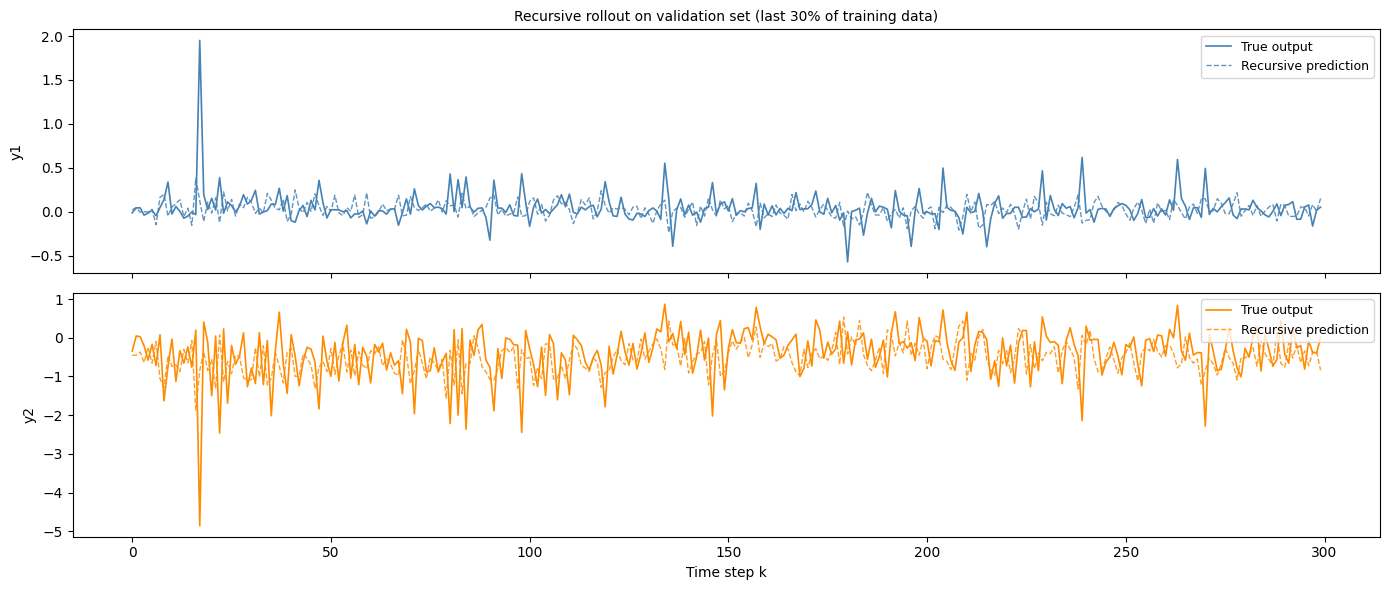

In [ ]:
val_err = np.abs(Ytr[split_idx:] - Y_val_rec)
ch_stats = pd.DataFrame({
    'channel': ['y1', 'y2'],
    'mae': [val_err[:, 0].mean(), val_err[:, 1].mean()],
    'max_abs_err': [val_err[:, 0].max(), val_err[:, 1].max()],
})

print('Recursive validation error summary by channel:')
print(ch_stats.to_string(index=False))

In [ ]:
# Retrain on full training set
m1_full, m2_full = fit_mimo_ridge(X_all, Y_next)

Yhat1 = recursive_rollout_mimo(Uts1, m1_full, m2_full, d=d, na=na, nb=nb)
Yhat2 = recursive_rollout_mimo(Uts2, m1_full, m2_full, d=d, na=na, nb=nb)

print(f'Yhat1 shape: {Yhat1.shape}, Yhat2 shape: {Yhat2.shape}')

out_path = PROJECT_ROOT / 'results' / 'predictions' / 'submission_from_notebook03.npz'
out_path.parent.mkdir(parents=True, exist_ok=True)
np.savez(out_path, Yhat1=Yhat1, Yhat2=Yhat2)
print(f'Saved predictions to: {out_path.resolve()}')

Yhat1 shape: (1000, 2), Yhat2 shape: (1000, 2)
Saved predictions to: C:\Users\pc\Desktop\M2\ML-stat\project\results\predictions\submission_from_notebook03.npz


### Sanity checks on outputs

Check required shape (1000, 2) and verify there are no NaN/Inf values before submission.

In [10]:
for name, Y in [('Yhat1', Yhat1), ('Yhat2', Yhat2)]:
    print(f'{name}  min={Y.min():.3f}  max={Y.max():.3f}  '
          f'any_nan={np.isnan(Y).any()}  any_inf={np.isinf(Y).any()}')

Yhat1  min=-1.877  max=1.003  any_nan=False  any_inf=False
Yhat2  min=-1.945  max=0.694  any_nan=False  any_inf=False


### Summary

Delay $d$ was first estimated from causal cross-correlation ($k \geq 0$), then validated on a wider grid.
Lag orders were selected with one-step validation NMSE over candidate sets for $(d, n_a, n_b)$.

For prediction, we used MIMO-aware regressors with two Ridge models and recursive rollout.
Recursive validation error is higher than one-step error, which is expected for long horizons.